In [48]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/iammustafatz/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [49]:
import pandas as pd
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("/kaggle/input/datasets/iammustafatz/diabetes-prediction-dataset/diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [52]:
df.shape

(100000, 9)

In [53]:
df.dtypes

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [54]:
df.duplicated().sum()

np.int64(3854)

In [55]:
df = df.drop_duplicates()

In [56]:
df["diabetes"].value_counts()

diabetes
0    87664
1     8482
Name: count, dtype: int64

<Axes: xlabel='diabetes'>

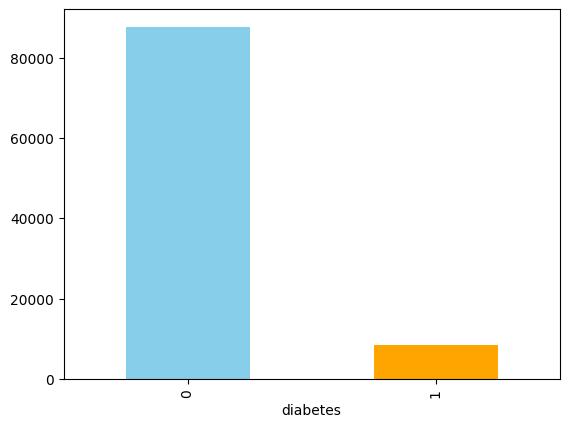

In [57]:
df["diabetes"].value_counts().plot(kind="bar", color=["skyblue", "orange"])

In [58]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output = False,
    handle_unknown = "ignore"
)

encoded = encoder.fit_transform(df[["gender", "smoking_history"]] )

In [59]:
encoded[:5]

array([[1., 0., 0., 0., 0., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 1., 0., 0., 0., 0.]])

In [60]:
encoded_df = pd.DataFrame(
    encoded,
    columns = encoder.get_feature_names_out(["gender", "smoking_history"])
)

df_preprocessing = pd.concat([encoded_df.reset_index(drop=True), df.drop(columns=["gender", "smoking_history"]).reset_index(drop=True)], axis = 1 )

df_preprocessing

,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,80.0,0,1,25.19,6.6,140,0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,54.0,0,0,27.32,6.6,80,0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,28.0,0,0,27.32,5.7,158,0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,36.0,0,0,23.45,5.0,155,0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,76.0,1,1,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96141,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,36.0,0,0,24.60,4.8,145,0
96142,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,17.37,6.5,100,0
96143,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,66.0,0,0,27.83,5.7,155,0
96144,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,24.0,0,0,35.42,4.0,100,0


In [61]:
from sklearn.model_selection import train_test_split
X = df_preprocessing.drop(columns = "diabetes")
Y = df_preprocessing["diabetes"]

In [62]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size= 0.2, random_state= 42)

In [63]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 1000)
model.fit(X_train, Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [64]:
prediction = model.predict(X_test)

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [66]:
accuracy = accuracy_score(Y_test, prediction)
accuracy

0.9575663026521061

In [67]:
CM = confusion_matrix(Y_test, prediction)
CM

array([[17336,   173],
       [  643,  1078]])

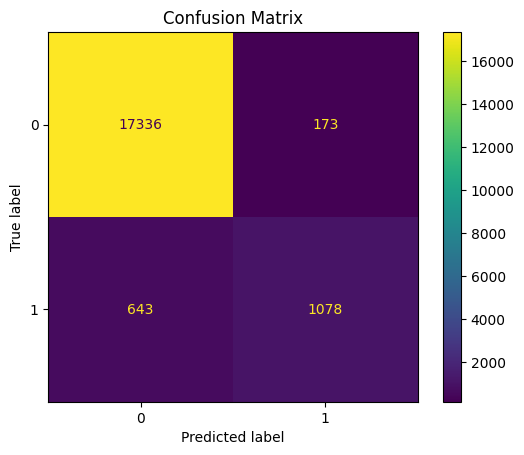

In [68]:
ConfusionMatrixDisplay.from_predictions(
    Y_test,
    prediction
)

plt.title("Confusion Matrix")
plt.show()

In [69]:
recall = recall_score(Y_test, prediction)
recall

0.6263800116211505

In [70]:
precision = precision_score(Y_test, prediction)
precision

0.8617106314948042

In [71]:
f1 = f1_score(Y_test, prediction, zero_division=0)
f1

0.7254374158815612

In [72]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    Y_train
)

In [73]:
model.fit(X_train_smote, y_train_smote)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [74]:
smote_predictions = model.predict(X_test)

In [75]:
acc_smote = accuracy_score(smote_predictions, Y_test)
acc_smote

0.884399375975039

In [76]:
recall_smote = recall_score(smote_predictions, Y_test)
recall_smote

0.42820366132723114

In [77]:
precision_smote = precision_score(smote_predictions, Y_test)
precision_smote

0.8698431144683324

In [78]:
f1_smote = f1_score(smote_predictions, Y_test)
f1_smote

0.5738930419781484

In [79]:
import joblib

# Replace 'model' with your actual trained model variable
joblib.dump(model, "/kaggle/working/diabetes_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [80]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/diabetes_model.joblib"))

/kaggle/working/diabetes_model.joblib

In [81]:
import joblib
import os

# Save the complete trained pipeline
os.makedirs("/kaggle/working", exist_ok=True)

joblib.dump(
    model,
    "/kaggle/working/diabetes_model.joblib"
)

print("Model saved successfully!")
print("File size:", round(
    os.path.getsize("/kaggle/working/diabetes_model.joblib") / (1024 * 1024),
    2
), "MB")

Model saved successfully!
File size: 0.0 MB
